In [19]:
import sklearn
print(sklearn.__version__)


1.9.1


In [11]:
%pip install numpy pandas matplotlib seaborn scikit-learn prettytable

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\zh com\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Live demo: (add after deployment)

In [12]:
# Heart Disease Prediction (Titanic-style, no Label Encoding)
# Dataset: UCI Heart Disease, Cleveland file (processed.cleveland.data)
# Inputs: age, sex, cp, thalach  (4 attributes)

# ===================== Step 1: Import Libraries =====================
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from prettytable import PrettyTable

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

Matplotlib is building the font cache; this may take a moment.


In [13]:
# ===================== Step 2: Load Sample Data =====================
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target",
]

sample_data = pd.read_csv(
    "processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?",
)

print("\nSample Data (first 10 rows):")
print("============================\n")
print(sample_data.head(10))




Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3


Number of Instances: 303
Number of Attributes: 14

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Rows before: 303  after removing missing: 297

Target distribution:
target
0    160
1    137
Name: count, dtype: int64

Columns used: ['age', 'sex', 'cp', 'thalach', 'target']


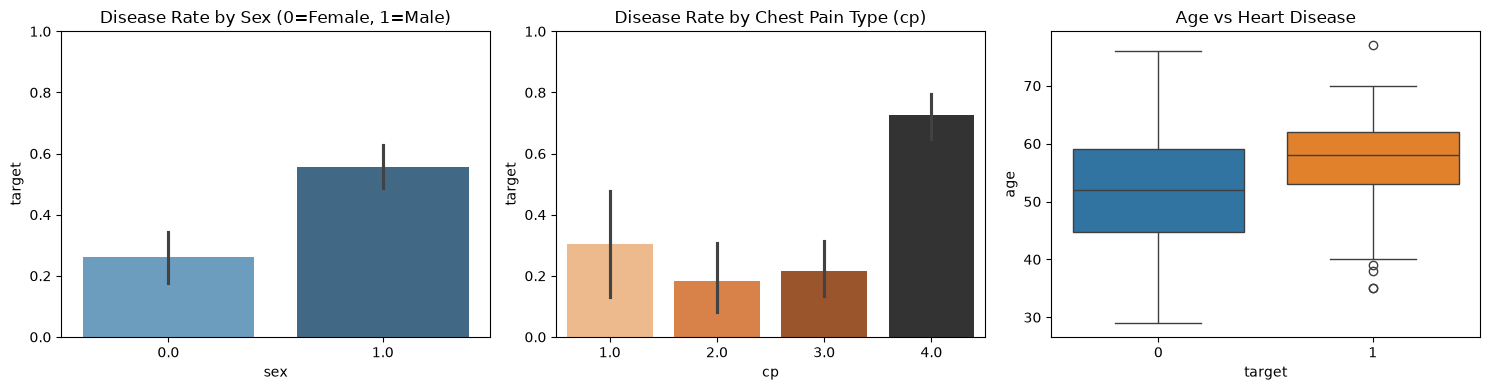

In [14]:
# ===================== Step 3.1: Understand Data =====================
print("\nNumber of Instances:", sample_data.shape[0])
print("Number of Attributes:", sample_data.shape[1])
print("\nMissing values per column:")
print(sample_data.isnull().sum())

# ===================== Step 3.2: Pre-process =====================
before = len(sample_data)
sample_data = sample_data.dropna().reset_index(drop=True)
after = len(sample_data)
print("\nRows before:", before, " after removing missing:", after)

# 0 = no disease, 1 = disease
sample_data["target"] = (sample_data["target"] > 0).astype(int)
print("\nTarget distribution:")
print(sample_data["target"].value_counts())

# Keep only 4 input attributes + the target
FEATURES = ["age", "sex", "cp", "thalach"]
sample_data = sample_data[FEATURES + ["target"]]
print("\nColumns used:", list(sample_data.columns))

# ===================== Step 3.3: Visualize =====================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(x="sex", y="target", data=sample_data, ax=axes[0],
            hue="sex", legend=False, palette="Blues_d")
axes[0].set_title("Disease Rate by Sex (0=Female, 1=Male)")
axes[0].set_ylim(0, 1)

sns.barplot(x="cp", y="target", data=sample_data, ax=axes[1],
            hue="cp", legend=False, palette="Oranges_d")
axes[1].set_title("Disease Rate by Chest Pain Type (cp)")
axes[1].set_ylim(0, 1)

sns.boxplot(x="target", y="age", data=sample_data, ax=axes[2],
            hue="target", legend=False)
axes[2].set_title("Age vs Heart Disease")

plt.tight_layout()
plt.show()



In [15]:
# ===================== Step 6.1: Split =====================
training_data, testing_data = train_test_split(
    sample_data,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data["target"],
)
training_data.to_csv("training-data.csv", index=False)
testing_data.to_csv("testing-data.csv", index=False)
print("\nTraining Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

# ===================== Step 6.2: Inputs and Labels =====================
input_vector_train = training_data.drop("target", axis=1)
output_label_train = training_data["target"]
input_vector_test = testing_data.drop("target", axis=1)
output_label_test = testing_data["target"]

# ===================== Step 6.3: Train SVC =====================
svc_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(gamma="auto", random_state=0)),
])
svc_model.fit(input_vector_train, output_label_train)
print("\nTrained:", svc_model)

# ===================== Step 6.4: Save Model =====================
with open("svc_heart_model.pkl", "wb") as f:
    pickle.dump(svc_model, f)
print("Saved: svc_heart_model.pkl")

# ===================== Step 6.5: Compare Models =====================
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(random_state=0, max_iter=1000)),
])
lr_model.fit(input_vector_train, output_label_train)

tree_model = DecisionTreeClassifier(random_state=0)
tree_model.fit(input_vector_train, output_label_train)

candidate_models = {
    "SVC": svc_model,
    "Logistic Regression": lr_model,
    "Decision Tree": tree_model,
}

table = PrettyTable()
table.field_names = ["Model", "Accuracy", "Precision", "Recall", "F1-score"]

for name, mdl in candidate_models.items():
    preds = mdl.predict(input_vector_test)
    rep = classification_report(
        output_label_test, preds, output_dict=True, zero_division=0
    )["weighted avg"]
    acc = round(accuracy_score(output_label_test, preds), 2)
    prec = round(rep["precision"], 2)
    rec = round(rep["recall"], 2)
    f1 = round(rep["f1-score"], 2)
    table.add_row([name, acc, prec, rec, f1])

print("\nModel Comparison on Testing Data:")
print(table)




Training Data shape: (237, 5)
Testing Data shape: (60, 5)

Trained: Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])
Saved: svc_heart_model.pkl

Model Comparison on Testing Data:
+---------------------+----------+-----------+--------+----------+
|        Model        | Accuracy | Precision | Recall | F1-score |
+---------------------+----------+-----------+--------+----------+
|         SVC         |   0.83   |    0.83   |  0.83  |   0.83   |
| Logistic Regression |   0.75   |    0.75   |  0.75  |   0.75   |
|    Decision Tree    |   0.72   |    0.72   |  0.72  |   0.71   |
+---------------------+----------+-----------+--------+----------+



Model loaded from svc_heart_model.pkl

Predictions (first 20 rows):
      age  sex   cp  thalach  target  Predictions
69   46.0  1.0  3.0    147.0       1            0
2    67.0  1.0  4.0    129.0       1            1
94   52.0  1.0  4.0    161.0       1            1
119  48.0  1.0  4.0    150.0       1            1
266  61.0  1.0  4.0    138.0       1            1
264  40.0  1.0  4.0    181.0       1            0
281  58.0  1.0  4.0    140.0       1            1
36   43.0  1.0  4.0    120.0       1            1
282  58.0  0.0  4.0    146.0       1            1
192  67.0  1.0  4.0    125.0       1            1
271  64.0  1.0  1.0    155.0       0            0
230  74.0  0.0  2.0    121.0       0            0
149  52.0  1.0  1.0    178.0       0            0
132  51.0  1.0  4.0    186.0       0            0
248  58.0  1.0  4.0    105.0       1            1
63   54.0  0.0  3.0    170.0       0            0
175  56.0  1.0  4.0    105.0       1            1
162  58.0  0.0  4.0    122.0   

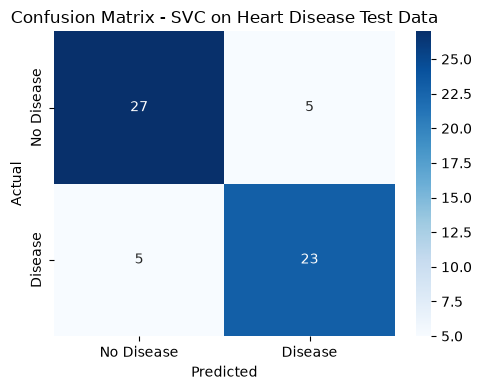

In [16]:
# ===================== Step 7: Testing Phase =====================
with open("svc_heart_model.pkl", "rb") as f:
    model = pickle.load(f)
print("\nModel loaded from svc_heart_model.pkl")

testing_results = testing_data.copy()
testing_results["Predictions"] = model.predict(input_vector_test)
testing_results.to_csv("model-predictions.csv", index=False)

print("\nPredictions (first 20 rows):")
print(testing_results.head(20))

final_acc = accuracy_score(
    testing_results["target"], testing_results["Predictions"]
)
print("\nAccuracy Score:", round(final_acc, 2))

print("\nClassification Report:")
print(classification_report(
    testing_results["target"],
    testing_results["Predictions"],
    target_names=["No Disease (0)", "Disease (1)"],
))

conf_matrix = confusion_matrix(
    testing_results["target"], testing_results["Predictions"]
)
print("Confusion Matrix:")
print(pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"],
))

plt.figure(figsize=(5, 4))
sns.heatmap(
    conf_matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Test Data")
plt.tight_layout()
plt.show()



In [17]:
# ===================== Step 8: Application Phase =====================
# Demo patient (4 inputs only)
age_input = 55       # age in years
sex_input = 1        # 1 = Male, 0 = Female
cp_input = 4         # chest pain type (1 to 4)
thalach_input = 130  # max heart rate achieved

# To type values yourself, replace a line with, e.g.:
# age_input = int(input("Enter age: "))

user_input = pd.DataFrame({
    "age": [age_input],
    "sex": [sex_input],
    "cp": [cp_input],
    "thalach": [thalach_input],
})
print("\nUser Input Feature Vector:")
print(user_input)

predicted = model.predict(user_input)[0]
if predicted == 1:
    prediction = "HEART DISEASE DETECTED"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)




User Input Feature Vector:
   age  sex  cp  thalach
0   55    1   4      130
+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|     HEART DISEASE DETECTED     |
+--------------------------------+


In [18]:
# ===================== Step 9: Feedback Phase =====================
improvements = [
    "Use a larger dataset so the model sees more patient types",
    "Use cross-validation instead of a single train/test split",
    "Tune SVC parameters (C, kernel, gamma) with GridSearchCV",
    "Try Random Forest or Gradient Boosting",
    "Ask a doctor to review wrong predictions (false negatives)",
]
print("\nPotential Improvements:")
for i, item in enumerate(improvements, 1):
    print(str(i) + ". " + item)


Potential Improvements:
1. Use a larger dataset so the model sees more patient types
2. Use cross-validation instead of a single train/test split
3. Tune SVC parameters (C, kernel, gamma) with GridSearchCV
4. Try Random Forest or Gradient Boosting
5. Ask a doctor to review wrong predictions (false negatives)
